# 3. Churn prediction model (IBM Telco)

**Goal:** score every customer's risk of churning, explain *why*, and decide **who should get a retention offer**.

**Plan**
1. Lock away a test set (20%) that is used **once**, at the very end.
2. Compare a baseline, **Logistic Regression** and **Random Forest** with 5-fold cross-validation on the training set.
3. Choose the model, then choose the **decision threshold by expected profit** instead of the default 0.5.
4. Explain the model with odds ratios and **SHAP**.
5. Turn it into business actions.

In [1]:
import sys
sys.path.append("..")

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

from src.churn_model import (MONTHS_OF_VALUE, OFFER_COST, SAVE_RATE, best_threshold, campaign_profit, evaluate,
                             logistic_odds_ratios, out_of_fold_proba, profit_curve, sensitivity, split, tune)
from src.config import BLUE, FIGURES_DIR, GREY, ORANGE
from src.explain import mean_abs_shap, shap_explanation
from src.plots import save, setup_style
from src.telco_data import FEATURES, load_clean

warnings.filterwarnings("ignore", category=FutureWarning)
setup_style()
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Train / test split

In [2]:
df = load_clean()
train, test, y_train, y_test = split(df)
print(f"train: {len(train):,} customers, churn {y_train.mean():.1%}")
print(f"test:  {len(test):,} customers, churn {y_test.mean():.1%}")

train: 5,634 customers, churn 26.5%
test:  1,409 customers, churn 26.5%


`stratify` keeps the churn rate the same (26.5%) in both parts. Everything below until section 5 uses **only the training set**.

## 2. Compare models with cross-validation

Each model is wrapped in a `Pipeline` with the preprocessing (scaling + one-hot encoding), so inside cross-validation the scaler is fitted only on each fold's training part. That avoids leaking information from the validation fold.

- **Baseline:** predicts the churn rate for everyone. Any real model must beat it.
- **Logistic Regression:** linear, fast, and each coefficient is interpretable.
- **Random Forest:** many decision trees; captures non-linear effects and interactions automatically.

Metric: **ROC-AUC**, which measures how well a model *ranks* churners above non-churners. It doesn't depend on the threshold or on the 26.5% / 73.5% class imbalance.

In [3]:
models = tune(train, y_train)
comparison = pd.DataFrame([{"model": m.name, "cv_roc_auc": m.cv_roc_auc, "cv_std": m.cv_roc_auc_std,
                            "best_settings": m.best_params} for m in models])
comparison

,model,cv_roc_auc,cv_std,best_settings
0,Baseline (predict nobody churns),0.500,0.000,{}
1,Logistic Regression,0.859,0.013,{'model__C': 1}
2,Random Forest,0.861,0.011,"{'model__max_depth': 8, 'model__min_samples_le..."


**Choosing the model**

Random Forest's cross-validated ROC-AUC is only about 0.002 higher than Logistic Regression's, while the variation between folds (std) is about 0.01. **The difference is noise.**

Rule used: *prefer the simpler model unless the more complex one wins by more than one standard deviation.* So the final model is **Logistic Regression**:
- every coefficient has a direct business meaning (odds ratios, section 6),
- it's faster, smaller and easier to monitor and retrain,
- its probabilities are well calibrated, which matters for the profit calculation.

Random Forest is kept to check that a very different model agrees on the drivers (section 6).

In [4]:
by_name = {m.name: m for m in models}
final = by_name["Logistic Regression"]
rf = by_name["Random Forest"]

## 3. Choosing *who to contact*: threshold by expected profit

A model outputs a churn **probability**; the business needs a **yes/no**: send an offer or not. The default cut-off of 0.5 is arbitrary. Instead we pick the cut-off that makes the most money under explicit assumptions (in `src/churn_model.py`; replace them with real figures):

| Assumption | Value |
|---|---|
| Cost per contacted customer (discount + agent time) | $50 |
| Share of real churners the offer keeps | 30% |
| Value of a kept customer | 12 × their monthly charge |

The threshold is chosen on **out-of-fold predictions on the training set**: each training customer is scored by a model that didn't see them. The test set stays untouched.

Chosen threshold: 0.21


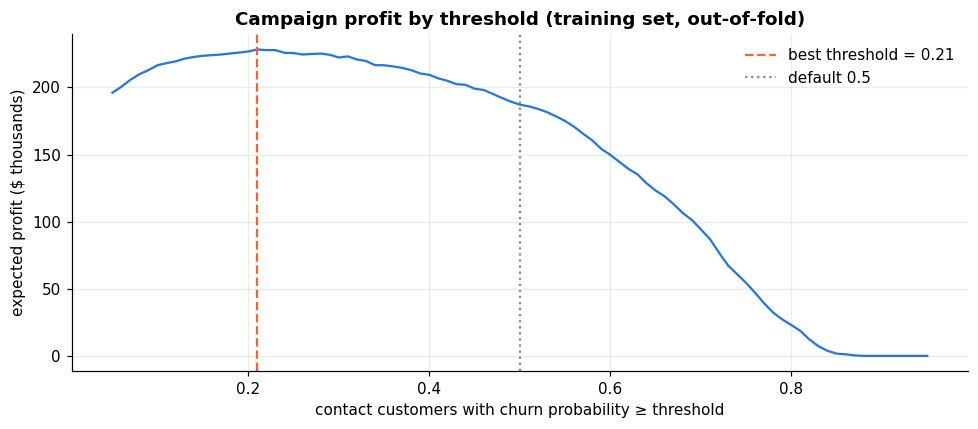

In [5]:
oof = out_of_fold_proba(final.pipeline, train, y_train)
curve = profit_curve(y_train, oof, train["monthly_charges"])
threshold = best_threshold(y_train, oof, train["monthly_charges"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve["threshold"], curve["profit"] / 1000, color=BLUE)
ax.axvline(threshold, color=ORANGE, linestyle="--", label=f"best threshold = {threshold:.2f}")
ax.axvline(0.5, color=GREY, linestyle=":", label="default 0.5")
ax.set(xlabel="contact customers with churn probability ≥ threshold", ylabel="expected profit ($ thousands)",
       title="Campaign profit by threshold (training set, out-of-fold)")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "model_profit_curve")
print(f"Chosen threshold: {threshold}")

A low threshold (about 0.2) is best. Missing a churner costs far more (a year of revenue) than an unnecessary $50 offer, so it pays to cast a wide net.

## 4. Final check on the untouched test set

In [6]:
rows = []
for m in models:
    rows.append({"model": m.name, **evaluate(m.pipeline, test, y_test, 0.5)})
rows.append({"model": "Logistic Regression @ profit threshold", **evaluate(final.pipeline, test, y_test, threshold)})
test_results = pd.DataFrame(rows).set_index("model")
test_results

,roc_auc,pr_auc,accuracy,precision,recall,f1,threshold
model,,,,,,,
Baseline (predict nobody churns),0.500,0.265,0.735,0.000,0.000,0.000,0.500
Logistic Regression,0.849,0.646,0.804,0.648,0.575,0.609,0.500
Random Forest,0.855,0.670,0.804,0.666,0.527,0.588,0.500
Logistic Regression @ profit threshold,0.849,0.646,0.725,0.489,0.856,0.623,0.210


**How to read this**
- The **baseline is 73.5% accurate while catching zero churners**. That's why accuracy is the wrong metric for imbalanced problems.
- Both real models reach **ROC-AUC ≈ 0.85** on unseen customers, close to their cross-validation scores, so there's no sign of overfitting.
- At the profit threshold, the model catches most churners (high **recall**). The price is lower **precision**: about half of the people contacted would have stayed anyway, and that's a deliberate trade-off.

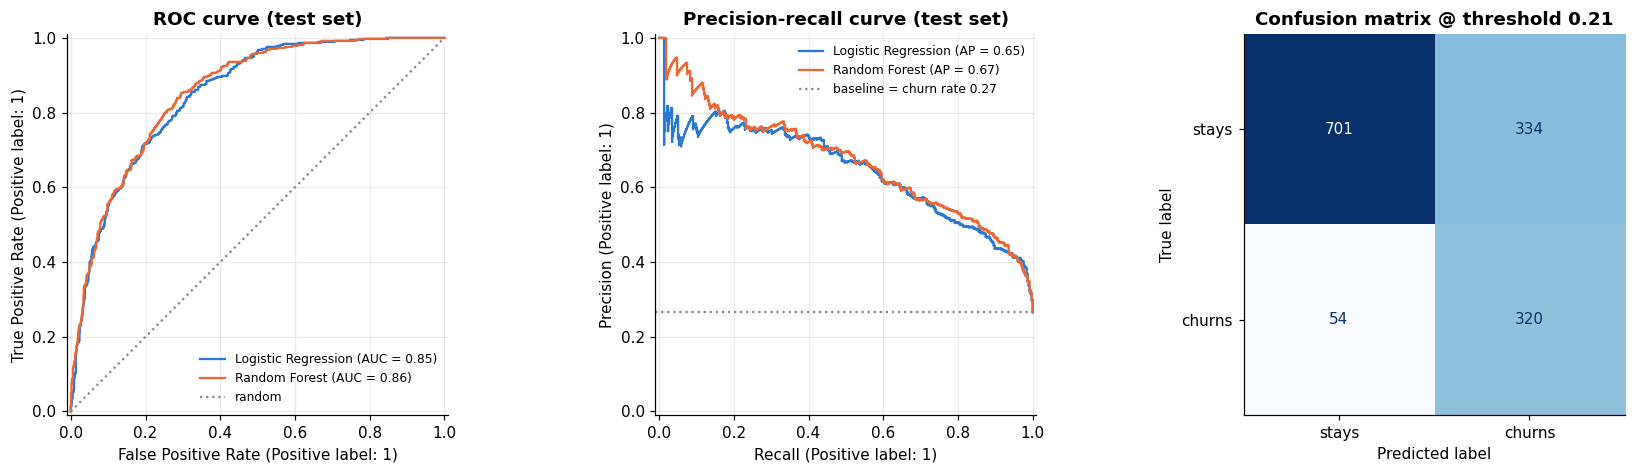

In [7]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.4))
for m, color in [(final, BLUE), (rf, ORANGE)]:
    RocCurveDisplay.from_estimator(m.pipeline, test[FEATURES], y_test, ax=ax1, name=m.name, color=color)
    PrecisionRecallDisplay.from_estimator(m.pipeline, test[FEATURES], y_test, ax=ax2, name=m.name, color=color)
ax1.plot([0, 1], [0, 1], color=GREY, linestyle=":", label="random")
ax1.set_title("ROC curve (test set)")
ax1.legend(frameon=False, fontsize=8)
ax2.axhline(y_test.mean(), color=GREY, linestyle=":", label=f"baseline = churn rate {y_test.mean():.2f}")
ax2.set_title("Precision-recall curve (test set)")
ax2.legend(frameon=False, fontsize=8)
proba_test = final.pipeline.predict_proba(test[FEATURES])[:, 1]
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= threshold).astype(int), ax=ax3, cmap="Blues",
                                        display_labels=["stays", "churns"], colorbar=False)
ax3.set_title(f"Confusion matrix @ threshold {threshold}")
ax3.grid(False)
fig.tight_layout()
save(fig, "model_test_curves")

In [8]:
campaigns = pd.DataFrame([
    {"strategy": "Contact nobody", "contacted": 0, "profit": 0.0},
    {"strategy": "Contact everyone", "contacted": len(test),
     "profit": campaign_profit(y_test, proba_test, test["monthly_charges"], 0.0)},
    {"strategy": "Model @ default 0.5", "contacted": int((proba_test >= 0.5).sum()),
     "profit": campaign_profit(y_test, proba_test, test["monthly_charges"], 0.5)},
    {"strategy": f"Model @ profit threshold {threshold}", "contacted": int((proba_test >= threshold).sum()),
     "profit": campaign_profit(y_test, proba_test, test["monthly_charges"], threshold)},
]).set_index("strategy")
campaigns["profit"] = campaigns["profit"].round(0)
campaigns

,contacted,profit
strategy,,
Contact nobody,0,0.000
Contact everyone,1409,"27,524.000"
Model @ default 0.5,332,"44,036.000"
Model @ profit threshold 0.21,654,"52,555.000"


On the 1,409 test customers, targeting with the model at the profit threshold earns the most. It beats both contacting everyone (wasting offers on loyal customers) and the default 0.5 threshold (missing too many churners). The absolute dollars depend on the assumptions, so the next cell checks whether the conclusion survives when they change.

### Sensitivity: what if the assumptions are wrong?
The threshold choice is repeated for 27 combinations of offer cost ($25 / $50 / $100), save rate (20% / 30% / 50%) and customer value (6 / 12 / 24 months). Each threshold is chosen on training data and judged on the test set.

In [9]:
sens = sensitivity(y_train, oof, train["monthly_charges"], y_test, proba_test, test["monthly_charges"])
beats_everyone = (sens["profit_tuned"] > sens["profit_contact_everyone"]).mean()
# Compare in dollars, not as a ratio: a ratio flips meaning when both profits are negative.
vs_default = sens["profit_tuned"] - sens["profit_default_0.5"]
print(f"Tuned model beats 'contact everyone' in {beats_everyone:.0%} of scenarios")
print(f"Tuned threshold >= default 0.5 in {(vs_default >= 0).sum()} of {len(sens)} scenarios; "
      f"worst shortfall ${-vs_default.min():,.0f}")
print(f"Best threshold ranges from {sens['best_threshold'].min()} to {sens['best_threshold'].max()}")
sens.round(2)

Tuned model beats 'contact everyone' in 100% of scenarios
Tuned threshold >= default 0.5 in 25 of 27 scenarios; worst shortfall $558
Best threshold ranges from 0.05 to 0.83


,offer_cost,save_rate,months_of_value,best_threshold,profit_contact_everyone,profit_default_0.5,profit_tuned
0,25,0.200,6,0.310,"-2,567.120","11,912.020","12,729.620"
1,25,0.200,12,0.210,"30,090.760","32,124.040","40,486.440"
2,25,0.200,24,0.080,"95,406.520","72,548.080","105,040.520"
3,25,0.300,6,0.210,"13,761.820","22,018.030","26,277.330"
4,25,0.300,12,0.100,"62,748.640","52,336.060","71,903.460"
5,25,0.300,24,0.050,"160,722.280","112,972.120","168,642.880"
6,25,0.500,6,0.130,"46,419.700","42,230.050","54,983.750"
7,25,0.500,12,0.050,"128,064.400","92,760.100","136,414.900"
8,25,0.500,24,0.050,"291,353.800","193,820.200","297,554.800"
9,50,0.200,6,0.560,"-37,792.120","3,612.020","3,827.720"


**Result:** using the model always beats contacting everyone, and in most scenarios the tuned threshold matches or beats the default 0.5. Where it doesn't, the shortfall is a few hundred dollars (about 2%): the threshold was tuned on training data, so test results carry some noise.

But the **best threshold moves a lot** (from about 0.05 to 0.8) as the assumptions change: cheap offers and valuable customers favour contacting many people, expensive offers favour few. **Getting the real offer cost and customer value from finance matters more than squeezing out extra model accuracy.**

## 5. Why do customers churn? Explaining the model

### 5a. Odds ratios (Logistic Regression)
`odds ratio > 1` raises the odds of churning, `< 1` lowers them, holding everything else constant. Numeric features are standardised, so their ratio is "per one standard deviation" (about 24.6 months for tenure).

,feature,coefficient,odds_ratio
0,dependents_Yes,-1.617,0.199
1,tenure_months,-1.259,0.284
2,internet_service_No,-1.140,0.320
3,contract_Two year,-0.847,0.429
4,internet_service_Fiber optic,0.709,2.032
5,total_charges,0.510,1.665
6,contract_Month-to-month,0.467,1.595
7,phone_service_Yes,-0.437,0.646
8,online_security_Yes,-0.362,0.696
9,paperless_billing_Yes,0.362,1.436


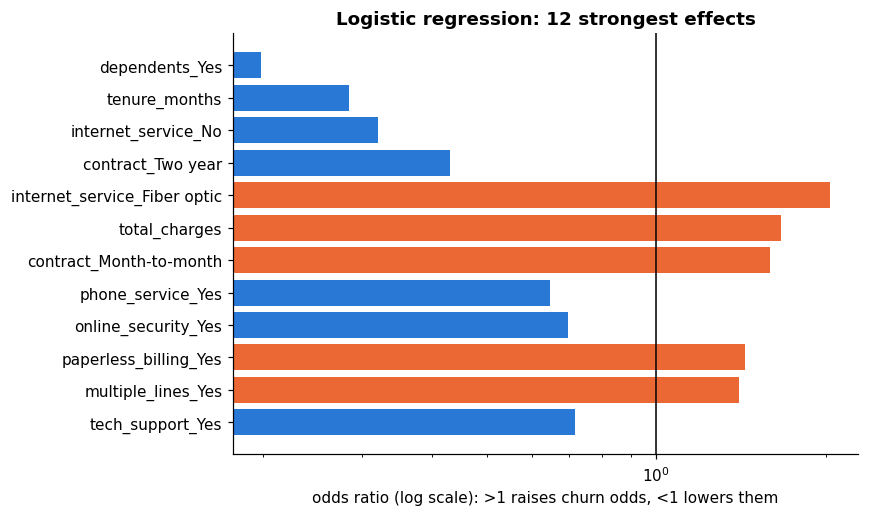

In [10]:
odds = logistic_odds_ratios(final.pipeline).head(12)
fig, ax = plt.subplots(figsize=(8, 4.8))
plot_df = odds.iloc[::-1]
ax.barh(plot_df["feature"], plot_df["odds_ratio"], color=[ORANGE if v > 1 else BLUE for v in plot_df["odds_ratio"]])
ax.axvline(1, color="black", linewidth=1)
ax.set_xscale("log")
ax.set(xlabel="odds ratio (log scale): >1 raises churn odds, <1 lowers them",
       title="Logistic regression: 12 strongest effects")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "model_odds_ratios")
odds

### 5b. SHAP: direction and size of each feature's effect
Each dot is one test customer. Position = how much that feature pushed *their* prediction towards churn (right) or staying (left). Colour = the feature's value (red high, blue low).

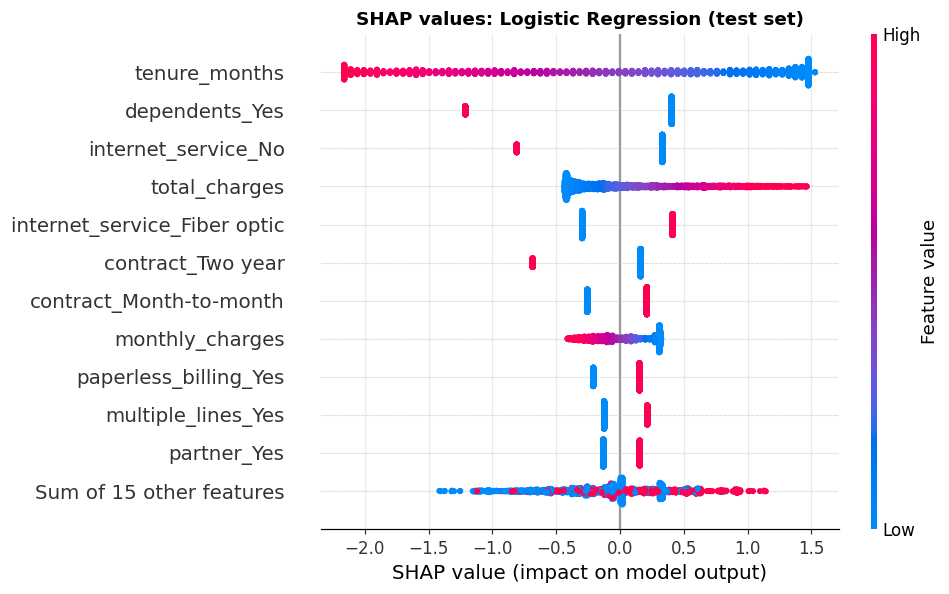

In [11]:
background = train.sample(200, random_state=0)
explanation = shap_explanation(final.pipeline, test, background)
plt.figure()
shap.plots.beeswarm(explanation, max_display=12, show=False)
plt.title("SHAP values: Logistic Regression (test set)")
plt.gcf().set_size_inches(9, 5.5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_shap_beeswarm.png", bbox_inches="tight", dpi=130)
plt.show()

### 5c. Do two very different models agree?
If a linear model and a tree ensemble pick the same top drivers, the drivers are a property of the **data**, not a quirk of one algorithm.

In [12]:
rf_explanation = shap_explanation(rf.pipeline, test.sample(400, random_state=0), background)
agreement = pd.DataFrame({
    "logistic_regression_rank": mean_abs_shap(explanation).rank(ascending=False).astype(int),
    "random_forest_rank": mean_abs_shap(rf_explanation).rank(ascending=False).astype(int),
}).sort_values("logistic_regression_rank").head(10)
agreement

 23%|=====               | 187/800 [00:11<00:36]       

 26%|=====               | 207/800 [00:12<00:34]       

 28%|======              | 228/800 [00:13<00:32]       

 31%|======              | 248/800 [00:14<00:31]       

 33%|=======             | 264/800 [00:15<00:30]       

...

 90%|==================  | 722/800 [00:39<00:04]       

 93%|=================== | 744/800 [00:40<00:03]       

 96%|=================== | 764/800 [00:41<00:01]       

 98%|===================| 783/800 [00:42<00:00]       

,logistic_regression_rank,random_forest_rank
tenure_months,1,2
dependents_Yes,2,4
internet_service_No,3,7
total_charges,4,5
internet_service_Fiber optic,5,3
contract_Two year,6,9
contract_Month-to-month,7,1
monthly_charges,8,6
paperless_billing_Yes,9,10
multiple_lines_Yes,10,17


Both models put **tenure, contract type, fiber internet and dependents** at the top. These are the drivers the business should act on.

**A lesson from comparing with the EDA:** electronic-check payers churned at 45% in notebook 2, yet in the model that feature ranks only about 22nd (LR) and 8th (RF). The reason: e-check payers are mostly month-to-month (78% vs 43% of others), newer (median tenure 18 vs 35 months) and on fiber (67% vs 32%). Once those are accounted for, little effect is left. **A strong association in a simple chart can be a marker of other factors**, which is exactly why we model drivers together.

**Caveat, correlated features:** `tenure_months` and `total_charges` are 0.83 correlated (total ≈ tenure × monthly charge). In the beeswarm, high total charges appear to *raise* churn while long tenure lowers it. The model splits one shared effect between two related columns, so read them as a pair, not separately.

### 5d. One customer, explained
For the customer with the highest predicted risk in the test set: which features drove their score? This is what a retention agent would see before calling.

Customer 5178-LMXOP: churn probability 88%


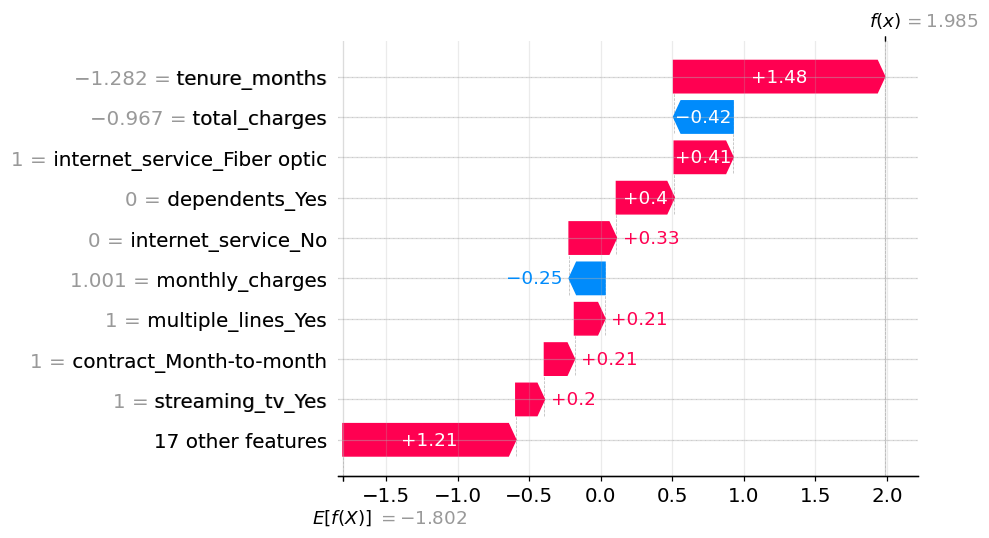

tenure_months                       1
monthly_charges                95.100
total_charges                  95.100
gender                           Male
senior_citizen                    Yes
partner                           Yes
dependents                         No
phone_service                     Yes
multiple_lines                    Yes
internet_service          Fiber optic
online_security                    No
online_backup                      No
device_protection                  No
tech_support                       No
streaming_tv                      Yes
streaming_movies                  Yes
contract               Month-to-month
paperless_billing                 Yes
payment_method       Electronic check
Name: 886, dtype: object

In [13]:
i = int(np.argmax(proba_test))
print(f"Customer {test.iloc[i]['customer_id']}: churn probability {proba_test[i]:.0%}")
plt.figure()
shap.plots.waterfall(explanation[i], max_display=10, show=False)
plt.gcf().set_size_inches(9, 5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_shap_one_customer.png", bbox_inches="tight", dpi=130)
plt.show()
test.iloc[i][FEATURES]

## 6. What-if: moving month-to-month customers to a one-year contract

The model can estimate how risk changes when one input changes. Here, every month-to-month customer in the test set is "switched" to a one-year contract and re-scored.

⚠️ **Caution:** this is a *model-based estimate of association*, not proof of cause. Customers who choose contracts may differ in ways the data doesn't show. A real decision should be confirmed with an **A/B test** (offer the contract discount to a random half of customers).

In [14]:
m2m = test[test["contract"] == "Month-to-month"].copy()
before = final.pipeline.predict_proba(m2m[FEATURES])[:, 1]
after = final.pipeline.predict_proba(m2m.assign(contract="One year")[FEATURES])[:, 1]
what_if = pd.Series({
    "month-to-month customers (test set)": len(m2m),
    "avg predicted churn now": before.mean(),
    "avg predicted churn on a one-year contract": after.mean(),
    "expected churners now": before.sum(),
    "expected churners after switch": after.sum(),
})
what_if

month-to-month customers (test set)          773.000
avg predicted churn now                        0.429
avg predicted churn on a one-year contract     0.293
expected churners now                        331.443
expected churners after switch               226.755
dtype: float64

## 7. Save results for the README and business report

In [15]:
summary = {
    "cv_roc_auc": {m.name: round(m.cv_roc_auc, 4) for m in models},
    "test": test_results.round(4).to_dict(orient="index"),
    "threshold": threshold,
    "campaigns": campaigns["profit"].to_dict(),
    "assumptions": {"offer_cost": OFFER_COST, "save_rate": SAVE_RATE, "months_of_value": MONTHS_OF_VALUE},
    "what_if_one_year_contract": {k: round(float(v), 3) for k, v in what_if.items()},
}
(FIGURES_DIR.parent / "model_metrics.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary["campaigns"], indent=2))

{
  "Contact nobody": 0.0,
  "Contact everyone": 27524.0,
  "Model @ default 0.5": 44036.0,
  "Model @ profit threshold 0.21": 52555.0
}
